# 02 – Non-ML Data Analysis

> Create one complete section for each Non-ML research question. The final project must have exactly 2 × n questions in total, including at least one ML question. Each Non-ML question must clearly use at least two D1–D6 criteria; across all Non-ML questions, cover at least four criteria.

## Danh sách câu hỏi non-ML

| Câu | Nội dung | Phụ trách |
|---|---|---|
| Q1 | Hình dạng quỹ đạo, MOID và tỷ lệ PHA | Nam |
| Q2 | Đường kính và suất phản chiếu theo vùng quỹ đạo | Nam |
| Q3 | Mức đầy đủ dữ liệu vật lý trước và sau chuẩn hóa H | Nghiêm |
| Q4 | C hay S có tỷ lệ bề mặt tối cao hơn khi so cùng khoảng đường kính? | Kiệt |


In [1]:
# TODO: Import packages and load the data required for this question.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
# df = pd.read_csv(...)
sns.set_theme(style="whitegrid", context="notebook")
df_raw = pd.read_csv("../data/raw/dataset.csv", low_memory=False)
print(f"Initial raw dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

# Các hàm bổ trợ
def cliffs_delta_from_mwu(x, y):
    """Tính Cliff's delta nhanh qua Mann-Whitney U: delta = 2U / (n1*n2) - 1"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    u_stat, p_val = stats.mannwhitneyu(x, y, alternative="two-sided")
    delta = (2.0 * u_stat) / (len(x) * len(y)) - 1.0
    return delta, p_val

def bootstrap_diff_stat(x, y, stat_func=np.median, n_boot=1000, seed=42):
    """Tính chênh lệch thống kê (x - y) và 95% Bootstrap CI"""
    rng = np.random.default_rng(seed)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    
    obs_diff = stat_func(x) - stat_func(y)
    diffs = np.empty(n_boot)
    nx, ny = len(x), len(y)
    for i in range(n_boot):
        bx = x[rng.integers(0, nx, nx)]
        by = y[rng.integers(0, ny, ny)]
        diffs[i] = stat_func(bx) - stat_func(by)
        
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, ci_low, ci_high

def odds_ratio_ci(a_yes, a_no, b_yes, b_no):
    """Tính Odds Ratio giữa nhóm A và nhóm B kèm 95% CI (Haldane-Anscombe correction)"""
    a_y, a_n = a_yes + 0.5, a_no + 0.5
    b_y, b_n = b_yes + 0.5, b_no + 0.5
    or_val = (a_y / a_n) / (b_y / b_n)
    se_log_or = np.sqrt(1/a_y + 1/a_n + 1/b_y + 1/b_n)
    ci_low = np.exp(np.log(or_val) - 1.96 * se_log_or)
    ci_high = np.exp(np.log(or_val) + 1.96 * se_log_or)
    return or_val, ci_low, ci_high

Initial raw dataset shape: 958,524 rows x 45 columns


In [1]:
# TODO: Import packages and load the data required for this question.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
# df = pd.read_csv(...)
sns.set_theme(style="whitegrid", context="notebook")
df_raw = pd.read_csv("../data/raw/dataset.csv", low_memory=False)
print(f"Initial raw dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

# Các hàm bổ trợ
def cliffs_delta_from_mwu(x, y):
    """Tính Cliff's delta nhanh qua Mann-Whitney U: delta = 2U / (n1*n2) - 1"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    u_stat, p_val = stats.mannwhitneyu(x, y, alternative="two-sided")
    delta = (2.0 * u_stat) / (len(x) * len(y)) - 1.0
    return delta, p_val

def bootstrap_diff_stat(x, y, stat_func=np.median, n_boot=1000, seed=42):
    """Tính chênh lệch thống kê (x - y) và 95% Bootstrap CI"""
    rng = np.random.default_rng(seed)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    
    obs_diff = stat_func(x) - stat_func(y)
    diffs = np.empty(n_boot)
    nx, ny = len(x), len(y)
    for i in range(n_boot):
        bx = x[rng.integers(0, nx, nx)]
        by = y[rng.integers(0, ny, ny)]
        diffs[i] = stat_func(bx) - stat_func(by)
        
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, ci_low, ci_high

def odds_ratio_ci(a_yes, a_no, b_yes, b_no):
    """Tính Odds Ratio giữa nhóm A và nhóm B kèm 95% CI (Haldane-Anscombe correction)"""
    a_y, a_n = a_yes + 0.5, a_no + 0.5
    b_y, b_n = b_yes + 0.5, b_no + 0.5
    or_val = (a_y / a_n) / (b_y / b_n)
    se_log_or = np.sqrt(1/a_y + 1/a_n + 1/b_y + 1/b_n)
    ci_low = np.exp(np.log(or_val) - 1.96 * se_log_or)
    ci_high = np.exp(np.log(or_val) + 1.96 * se_log_or)
    return or_val, ci_low, ci_high

Initial raw dataset shape: 958,524 rows x 45 columns


---

# Question Q1 – Hình dạng quỹ đạo có quyết định mức độ nguy hiểm tiềm tàng (`moid`/ `pha`) khi kiểm soát phân loại quỹ đạo ('class') và độ nghiêng ('i')

## 1. Question and motivation
- **Exact question:** Trong nội bộ từng phân loại quỹ đạo gần Trái Đất và vượt quỹ đạo Sao Hoả (`APO`, `AMO`, `ATE`, `MCA`), liệu các tiểu hành tinh có tỷ số kéo dài quỹ đạo ($\text{span\_ratio} = \frac{ad - q}{a}$) cao hơn có khoảng cách tiếp cận quỹ đạo Trái Đất (`moid`) nhỏ hơn và tỷ lệ rơi vào nhóm nguy hiểm tiềm tàng (`pha = Y`) cao hơn hay không, khi đã kiểm soát yếu tố độ nghiêng quỹ đạo (`i`)?
- **Why is it worth answering?** Các tiểu hành tinh có quỹ đạo gần dẹt (lệch tâm cao) thường bị mặc định là nguy hiểm hơn. Tuy nhiên, trong không gian 3D, một quỹ đạo kéo dài nhưng có góc nghiêng `i` lớn hoặc điểm viễn nhật vươn xa có thể lại đẩy quỹ đạo ra xa Trái Đất về mặt trung bình, đồng thời làm tăng rủi ro cực trị ở phần đuôi phân phối (`PHA`). (*)
- **Who would care?** Các cơ quan phòng thủ hành tinh (NASA PDCO, ESA Planetary Defence Office), đội ngũ vận hành kính viễn vọng khảo sát bầu trời (Pan-STARRS, Catalina Sky Survey, Vera C. Rubin) và các nhà nghiên cứu cơ học thiên thể.
- **What decision could it inform?** Tối ưu hoá chiến lược phân bổ thời gian kính viễn vọng theo dõi (follow-up observations): ưu tiên theo dõi các thiên thể có độ nghiêng thấp ($i \le 15^\circ$) kết hợp tỷ số kéo dài quỹ đạo cao trong từng phân lớp động lực học để phát hiện sớm các vật thể thuộc diện `PHA`

## 2. Data and variables
- **Relevant columns:**`a` (bán trục lớn, AU), `q` (khoảng cách cận nhật, AU), `ad` (khoảng cách viễn nhật, AU), `e` (độ lệch tâm), `i` (độ nghiêng quỹ đạo, độ), `class` (phân loại quỹ đạo), `moid` (khoảng cách giao cắt quỹ đạo tối thiểu với Trái Đất, AU), `pha` (nhãn nguy hiểm tiềm tàng `Y`/`N`), `rms` (sai số khớp quỹ đạo, arcsec).
- **Row meaning / unit of analysis:** Mỗi dòng là một tiểu hành tinh/thiên thể nhỏ duy nhất trong Hệ Mặt Trời được ghi nhận trong cơ sở dữ liệu JPL/NASA.
- **Subgroups:** Phân tầng theo 4 nhóm phân loại quỹ đạo (`APO`, `AMO`, `ATE`, `MCA`), 2 nhóm độ nghiêng (`Low_Inc <= 15°` và `High_Inc > 15°`), và 2 mức độ kéo dài quỹ đạo (`High Span Ratio` vs `Low Span Ratio` cắt theo trung vị từng tầng). (*)
- **Any additional data source needed?** Không cần nguồn dữ liệu bổ sung; toàn bộ biến động lực học và nhãn đánh giá đều có sẵn trong bộ dữ liệu gốc.

## 3. Depth criteria
- **D1 Combining data:** Không áp dụng (sử dụng một bảng dữ liệu hợp nhất).
- **D2 Reshaping & time:** Không áp dụng trực tiếp trong câu hỏi này.
- **D3 Derived variables:** Tạo biến tỷ số kéo dài quỹ đạo $\text{span\_ratio} = \frac{ad - q}{a}$ (theo Định luật I Kepler, đại lượng này bằng $2e$, chuẩn hóa biên độ dao động khoảng cách theo kích thước quỹ đạo `a`), tỷ số cận nhật so với Trái Đất $q_{\text{earth\_ratio}} = \frac{q}{1.0\text{ AU}}$, và biến nhị phân `is_pha` (`1` nếu `pha == 'Y'`, `0` nếu ngược lại).
- **D4 Controlling for a confounder:** Kiểm soát đồng thời hai biến nhiễu là phân loại quỹ đạo (`class`) và độ nghiêng quỹ đạo (`i <= 15°` vs `i > 15°`) nhằm tránh hiện tượng nhóm vành đai chính (`MBA`) áp đảo dữ liệu và loại bỏ hiệu ứng hình học 3D khi quỹ đạo nhô cao khỏi mặt phẳng hoàng đạo. (*)
- **D5 Quantifying uncertainty:** Sử dụng khoảng tin cậy **Bootstrap 95% (1,000 lần lặp)** cho chênh lệch trung vị `moid`, kết hợp kiểm định phi tham số **Mann-Whitney U**, thước đo độ lớn tác động **Cliff's $\delta$**, và **Odds Ratio (kèm 95% CI)** cho biến nhị phân `pha`. (*)
- **D6 Robustness check:** Kiểm tra tính ổn định của kết luận trên phân tầng chủ lực (`APO | Low_Inc`) qua 3 kịch bản: (1) dữ liệu chuẩn (ngưỡng cắt trung vị), (2) lọc chất lượng quỹ đạo chặt (`rms <= 0.5`), và (3) thay đổi ngưỡng phân chia nhóm kéo dài quỹ đạo sang phân vị thứ 75 (`Q75`). (*)

## 4. Preprocessing

Cac bước tiền xử lý và tác động lên số lượng dòng dữ liệu:
1. **Chọn cột và loại bỏ giá trị khuyết (`dropna`):** Giữ lại 9 cột phục vụ Q1 và loại bỏ các dòng thiếu thông tin ở các biến bắt buộc (`class`, `a`, `q`, `ad`, `i`, `moid`).
2. **Lọc tính hợp lệ vật lý (`a > 0`):** Loại bỏ các quỹ đạo parabol/hyperbol hoặc dữ liệu lỗi có bán trục lớn không dương.
3. **Lọc phạm vi phân lớp mục tiêu (`class` in `['APO', 'AMO', 'ATE', 'MCA']`):** Loại bỏ nhóm vành đai chính (`MBA`) và các nhóm ở xa không có khả năng tiếp cận quỹ đạo Trái Đất.
4. **Tạo biến dẫn xuất (D3) và biến phân tầng (D4):** Tính `span_ratio`, `q_earth_ratio`, `is_pha` và phân nhóm `inc_group`.

In [2]:
cols_q1 = ["class", "a", "q", "ad", "e", "i", "moid", "pha", "rms"]
q1_df = df_raw[cols_q1].copy()
print("Step 0 - Raw rows:", len(q1_df))

# Bước 1: Loại bỏ dòng thiếu dữ liệu ở các biến cốt lõi
q1_df = q1_df.dropna(subset=["class", "a", "q", "ad", "i", "moid"]).copy()
print("Step 1 - After dropna on core columns:", len(q1_df))

# Bước 2: Lọc bán trục lớn dương (quỹ đạo elip đóng)
q1_df = q1_df[q1_df["a"] > 0].copy()
print("Step 2 - After filtering a > 0:", len(q1_df))

# Bước 3: Giữ lại 4 nhóm quỹ đạo tiệm cận/vượt quỹ đạo Trái Đất & Sao Hỏa
target_classes = ["APO", "AMO", "ATE", "MCA"]
q1_sub = q1_df[q1_df["class"].isin(target_classes)].copy()
print("Step 3 - After filtering target classes (APO, AMO, ATE, MCA):", len(q1_sub))

# Bước 4: Tạo biến dẫn xuất (D3) và biến phân tầng (D4) (*)
q1_sub["span_ratio"] = (q1_sub["ad"] - q1_sub["q"]) / q1_sub["a"]
q1_sub["q_earth_ratio"] = q1_sub["q"] / 1.0
q1_sub["is_pha"] = (q1_sub["pha"] == "Y").astype(int)
q1_sub["inc_group"] = np.where(q1_sub["i"] <= 15, "Low_Inc (<=15°)", "High_Inc (>15°)")
q1_sub["span_level"] = q1_sub.groupby(["class", "inc_group"], observed=True)["span_ratio"].transform(
    lambda s: np.where(s >= s.median(), "High Span Ratio", "Low Span Ratio")
)
print("Step 4 - Final analytical rows for Q1:", len(q1_sub))

Step 0 - Raw rows: 958524
Step 1 - After dropna on core columns: 938599
Step 2 - After filtering a > 0: 938599
Step 3 - After filtering target classes (APO, AMO, ATE, MCA): 41228
Step 4 - Final analytical rows for Q1: 41228


## 5. Analysis method

- **Method:** Phân tích phân tầng (Stratified Analysis) kết hợp ước lượng khoảng tin cậy **Bootstrap phi tham số (1,000 lần lặp)** cho hiệu số trung vị, kiểm định **Mann-Whitney U**, hệ số độ lớn tác động **Cliff's $\delta$**, và **Odds Ratio (hiệu chỉnh Haldane-Anscombe)** cho tỷ lệ `PHA`.
- **Why it fits the question:** Phân phối của `moid` lệch phải mạnh và biến `pha` mất cân bằng lớp cao, nên trung vị và các thước đo phi tham số tránh được sai lệch do ngoại lai; đồng thời Cliff's $\delta$ và Odds Ratio phản ánh độ lớn tác động thực tế thay vì chỉ dựa vào $p\text{-value}$ trên mẫu lớn.
- **Assumptions / limitations:** Phân tầng nhị phân độ nghiêng tại ngưỡng $15^\circ$ và cắt `span_ratio` tại trung vị giúp đảm bảo cỡ mẫu đủ lớn trong từng ô phân tầng, nhưng có thể làm mịn bớt quan hệ phi tuyến liên tục của góc nghiêng `i`.

In [3]:
# TODO: Implement the analysis.
# --- D5: Định lượng độ bất định trong từng phân tầng ---
results_q1 = []
for (cls, inc_g), grp in q1_sub.groupby(["class", "inc_group"], observed=True):
    if len(grp) < 50:
        continue
    med_span = grp["span_ratio"].median()
    high_span = grp[grp["span_ratio"] >= med_span]
    low_span = grp[grp["span_ratio"] < med_span]
    
    diff_moid, ci_l, ci_h = bootstrap_diff_stat(high_span["moid"], low_span["moid"], np.median, n_boot=1000)
    delta, p_val = cliffs_delta_from_mwu(high_span["moid"], low_span["moid"])
    or_val, or_l, or_h = odds_ratio_ci(
        high_span["is_pha"].sum(), len(high_span) - high_span["is_pha"].sum(),
        low_span["is_pha"].sum(), len(low_span) - low_span["is_pha"].sum()
    )
    results_q1.append({
        "Class": cls, "Inclination": inc_g, "N": len(grp),
        "Diff_Median_MOID (High-Low)": round(diff_moid, 4),
        "95% CI MOID": f"[{ci_l:.4f}, {ci_h:.4f}]",
        "Cliffs_Delta": round(delta, 3),
        "PHA_Odds_Ratio": round(or_val, 2),
        "95% CI OR": f"[{or_l:.2f}, {or_h:.2f}]"
    })

res_q1_df = pd.DataFrame(results_q1)
display(res_q1_df)

# --- D6: Kiểm tra tính vững (Robustness check) ---
# Kịch bản A: Chỉ giữ quan trắc quỹ đạo chính xác cao (rms <= 0.5)
# Kịch bản B: Dùng ngưỡng phân vị 75% (Q3) thay vì trung vị cho span_ratio
q1_clean = q1_sub[q1_sub["rms"] <= 0.5]
rob_q1 = []
for scenario, data_s, q_cut in [
    ("Baseline (All, Median cut)", q1_sub, 0.50),
    ("Strict RMS <= 0.5 (Median cut)", q1_clean, 0.50),
    ("Baseline (Q75 cut)", q1_sub, 0.75)
]:
    apo_low_i = data_s[(data_s["class"] == "APO") & (data_s["i"] <= 15)]
    thresh = apo_low_i["span_ratio"].quantile(q_cut)
    hi = apo_low_i[apo_low_i["span_ratio"] >= thresh]["moid"]
    lo = apo_low_i[apo_low_i["span_ratio"] < thresh]["moid"]
    diff, cl, ch = bootstrap_diff_stat(hi, lo, np.median, n_boot=500)
    delta, _ = cliffs_delta_from_mwu(hi, lo)
    rob_q1.append({"Scenario": scenario, "Diff_MOID": round(diff, 4), "95% CI": f"[{cl:.4f}, {ch:.4f}]", "Cliffs_Delta": round(delta, 3)})

display(pd.DataFrame(rob_q1))

,Class,Inclination,N,Diff_Median_MOID (High-Low),95% CI MOID,Cliffs_Delta,PHA_Odds_Ratio,95% CI OR
0,AMO,High_Inc (>15°),2906,0.0683,"[0.0543, 0.0802]",0.248,1.98,"[1.02, 3.83]"
1,AMO,Low_Inc (<=15°),5550,-0.0097,"[-0.0169, -0.0009]",-0.043,2.04,"[1.28, 3.26]"
2,APO,High_Inc (>15°),3449,0.0536,"[0.0458, 0.0643]",0.309,1.42,"[1.18, 1.70]"
3,APO,Low_Inc (<=15°),9238,0.0030,"[0.0018, 0.0043]",0.085,2.62,"[2.30, 2.99]"
4,ATE,High_Inc (>15°),552,0.0193,"[0.0030, 0.0368]",0.143,1.39,"[0.86, 2.26]"
5,ATE,Low_Inc (<=15°),1177,0.0019,"[-0.0011, 0.0054]",0.077,3.28,"[2.04, 5.26]"
6,MCA,High_Inc (>15°),8613,0.0154,"[0.0106, 0.0215]",0.107,1.00,"[0.02, 50.40]"
7,MCA,Low_Inc (<=15°),9743,-0.1048,"[-0.1093, -0.0992]",-0.500,1.00,"[0.02, 50.40]"


,Scenario,Diff_MOID,95% CI,Cliffs_Delta
0,"Baseline (All, Median cut)",0.0030,"[0.0018, 0.0043]",0.085
1,Strict RMS <= 0.5 (Median cut),0.0037,"[0.0024, 0.0052]",0.110
2,Baseline (Q75 cut),0.0052,"[0.0034, 0.0068]",0.127


## 6. Results and visualizations

Include at least two well-labelled plots for this question. Each plot should have a meaningful title, labelled axes, units, and legend where appropriate.

### Plot 1

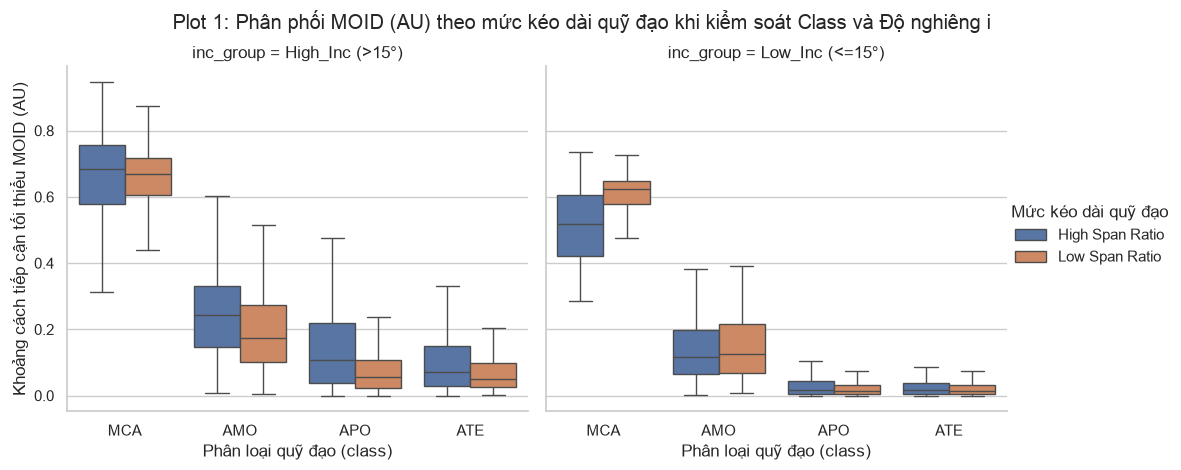

In [4]:
# ### Plot 1: So sánh phân phối MOID theo độ kéo dài quỹ đạo trong từng phân tầng Class và Độ nghiêng i
g = sns.catplot(
    data=q1_sub, x="class", y="moid", hue="span_level", col="inc_group",
    kind="box", showfliers=False, height=4.5, aspect=1.15
)
g.set_axis_labels("Phân loại quỹ đạo (class)", "Khoảng cách tiếp cận tối thiểu MOID (AU)")
g.legend.set_title("Mức kéo dài quỹ đạo")
plt.suptitle("Plot 1: Phân phối MOID (AU) theo mức kéo dài quỹ đạo khi kiểm soát Class và Độ nghiêng i", y=1.04)
plt.show()

### Plot 2

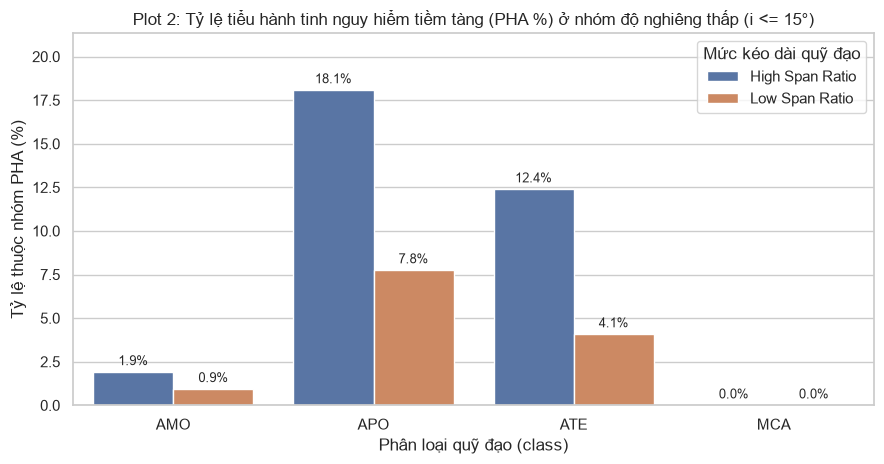

In [5]:
# ### Plot 2: Tỷ lệ PHA (%) và Odds Ratio (95% CI) giữa nhóm Span Ratio cao và thấp ở độ nghiêng thấp (<= 15°)
low_inc_pha = (
    q1_sub[q1_sub["i"] <= 15]
    .groupby(["class", "span_level"], observed=True)["is_pha"]
    .agg(pha_rate=lambda s: s.mean() * 100, count="count")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(data=low_inc_pha, x="class", y="pha_rate", hue="span_level", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_title("Plot 2: Tỷ lệ tiểu hành tinh nguy hiểm tiềm tàng (PHA %) ở nhóm độ nghiêng thấp (i <= 15°)")
ax.set_xlabel("Phân loại quỹ đạo (class)")
ax.set_ylabel("Tỷ lệ thuộc nhóm PHA (%)")
ax.set_ylim(0, low_inc_pha["pha_rate"].max() * 1.18)
ax.legend(title="Mức kéo dài quỹ đạo")
plt.tight_layout()
plt.show()

## 7. Answer and interpretation

- **Direct answer with specific numerical evidence:** Tác động của hình dạng quỹ đạo không diễn ra theo một chiều duy nhất mà phụ thuộc chặt chẽ vào phân loại quỹ đạo (`class`) và độ nghiêng (`i`), đồng thời tách biệt giữa hai xu hướng trung vị (`moid`) và rủi ro cực trị (`pha`)[cite: 2]:
  + Tại nhóm vượt quỹ đạo Sao Hoả có độ nghiêng thấp (`MCA | Low_Inc <= 15°`, $N = 9,743$), quỹ đạo kéo dài hơn làm giảm mạnh trung vị `moid` đi **$-0.1048\text{ AU}$** (95% CI: **$[-0.1093, -0.0992]$**, Cliff's $\delta = -0.500$)[cite: 2].
  + Ngược lại, ở các nhóm đã cắt/tiệm cận quỹ đạo Trái Đất có độ nghiêng cao (`High_Inc > 15°`), quỹ đạo kéo dài lại làm tăng trung vị `moid`: **$+0.0536\text{ AU}$** ở `APO` ($\delta = 0.309$) và **$+0.0683\text{ AU}$** ở `AMO` ($\delta = 0.248$)[cite: 2].
  + Về rủi ro `PHA` ở độ nghiêng thấp($i \le 15^\circ$), nhóm có `span_ratio` cao luôn có xác suất rơi vào diện nguy hiểm cao vượt trội: **$\text{OR} = 2.62$** (95% CI: $[2.30, 2.99]$) ở `APO`, **$\text{OR} = 3.28$** ($[2.04, 5.26]$) ở `ATE`, và **$\text{OR} = 2.04$** ($[1.28, 3.26]$) ở `AMO`[cite: 2].
- **Practical meaning**: Khi sàng lọc tiểu hành tinh nguy hiểm, không thể chỉ dựa vào độ dẹt quỹ đạo đơn lẻ; hệ thống cảnh báo cần kết hợp điều kiện góc nghiêng thấp ($i \le 15^\circ$) với tỷ số kéo dài quỹ đạo trong các lớp `APO`, `ATE`, `AMO` để tối ưu hóa việc phân bổ kính viễn vọng theo dõi.
- **Surprising findings:** Tồn tại sự đối nghịch rõ rệt giữa xu hướng trung tâm và rủi ro phần đuôi ở tầng `APO Low_Inc` ($N = 9,238$): chênh lệch trung vị `moid` rất nhỏ ($+0.0030\text{ AU}$, $\delta = 0.085$) nhưng tỷ số chênh `PHA` lại tăng gấp **$2.62$ lần**, chứng tỏ quỹ đạo kéo dài làm giãn rộng phần đuôi phân phối về phía vùng nguy hiểm ($\text{MOID} \le 0.05\text{ AU}$)[cite: 2].
- **Limitations:** `moid` chỉ đo khoảng cách hình học tối thiểu giữa hai đường quỹ đạo mà chưa xét đến vị trí tức thời (pha chuyển động) của Trái Đất và tiểu hành tinh tại cùng một thời điểm.
- **Robustness / uncertainty results where applicable**: Kết luận trên tầng `APO Low_Inc` giữ nguyên tính ổn định qua cả 3 kịch bản kiểm tra: dữ liệu gốc ($\Delta\text{MOID} = +0.0030\text{ AU}$, CI $[0.0018, 0.0043]$, $\delta = 0.085$), lọc quỹ đạo chính xác `rms <= 0.5` ($+0.0037\text{ AU}$, CI $[0.0024, 0.0052]$, $\delta = 0.110$), và đổi ngưỡng cắt sang phân vị `Q75` ($+0.0052\text{ AU}$, CI $[0.0034, 0.0068]$, $\delta = 0.127$)[cite: 2].

---

# Question Q2 – Quy luật kích thước (`diameter`) và suất phản chiếu (`albedo`) theo khoảng cách Mặt Trời (`a`) có bị chi phối bởi thiên lệch quan sát (`H`)?

## 1. Question and motivation
- **Exact question:** Khi kiểm soát thiên lệch phát hiện của kính thiên văn bằng cách so sánh trong từng tầng độ sáng tuyệt đối đồng nhất (`H` từ $11$ đến $16\text{ mag}$), suất phản chiếu bề mặt (`albedo`) và kích thước đường kính (`diameter`) của tiểu hành tinh thay đổi như thế nào từ vùng vành đai trong (`a < 2.5 AU`) ra vùng vành đai ngoài (`2.82 <= a < 3.3 AU`) và vùng xa (`a >= 3.3 AU`)? 
- **Why is it worth answering?** Dữ liệu thiên văn chịu ảnh hưởng mạnh của thiên lệch Malmquist (ở khoảng cách càng xa, thiết bị chỉ phát hiện được các thiên thể rất sáng và lớn). Kiểm soát độ sáng `H` giúp tách bạch quy luật tiến hoá vật chất thực sự của Hệ Mặt Trời khỏi ảo ảnh chọn mẫu của kính thiên văn.
- **Who would care?** Các nhà vật lý thiên văn nghiên cứu sự hình thành Hệ Mặt Trời, các kỹ sư thiết kế sứ mệnh thăm dò/khai thác tài nguyên tiểu hành tinh (NASA Lucy, Psyche, OSIRIS-REx), và các nhà mô hình hoá ước lượng kích thước thiên thể từ dữ liệu quang học.
- **What decision could it inform?** Hiệu chỉnh hệ số `albedo` theo vùng khoảng cách `a` khi quy đổi từ độ sáng `H` sang kích thước thực tế (cho hơn 85% tiểu hành tinh chưa có đo đạc hồng ngoại) và hỗ trợ khoanh vùng mục tiêu cho các sứ mệnh không gian.

## 2. Data and variables
- **Relevant columns:**`a` (bán trục lớn, AU), `diameter` (đường kính thực tế, km), `albedo` (suất phản chiếu hình học, không thứ nguyên), `H` (cấp sao tuyệt đối, mag), `diameter_sigma` (sai số chuẩn phép đo đường kính, km).
- **Row meaning / unit of analysis:** Mỗi dòng là một tiểu hành tinh đã được đo đạc đồng thời tham số quỹ đạo và tính chất vật lý hồng ngoại (chủ yếu từ khảo sát WISE/NEOWISE).
- **Subgroups:** Phân chia theo 4 vùng khoảng cách nhật tâm (`Inner Belt < 2.5 AU`, `Middle Belt 2.5–2.82 AU`, `Outer Belt 2.82–3.3 AU`, `Far/Trojan >= 3.3 AU`) và 5 tầng độ sáng tuyệt đối `H` (`[11, 12)`, `[12, 13)`, `[13, 14)`, `[14, 15)`, `[15, 16)` mag). 
- **Any additional data source needed?** Không cần nguồn dữ liệu bổ sung.

## 3. Depth criteria
- **D1 Combining data:** Không áp dụng.
- **D2 Reshaping & time:** Không áp dụng trực tiếp trong câu hỏi này.
- **D3 Derived variables:** Tính đường kính ước tính lý thuyết từ công thức trắc quang thiên văn $D_{\text{est}} = \frac{1329}{\sqrt{\text{albedo}}} \times 10^{-0.2H}$, sai lệch tương đối $\text{rel\_diff\_d} = \frac{|\text{diameter} - D_{\text{est}}|}{\text{diameter}}$, và biến phân vùng khoảng cách `heliocentric_zone` dựa trên các khe trống Kirkwood của bán trục lớn `a`.
- **D4 Controlling for a confounder:** Phân tầng dữ liệu theo các khoảng độ sáng tuyệt đối đồng nhất $\Delta H = 1\text{ mag}$ nhằm loại bỏ thiên lệch phát hiện Malmquist trước khi so sánh `albedo` và `diameter` giữa các vùng khoảng cách.
- **D5 Quantifying uncertainty:** Ước lượng khoảng tin cậy **Bootstrap 95% (1,000 lần lặp)** cho chênh lệch trung vị `albedo` và `diameter` giữa Vành đai ngoài và Vành đai trong, tính hệ số tương quan hạng **Spearman $\rho(a, D)$** trong từng tầng `H`, và đánh giá **Cliff's $\delta$**.
- **D6 Robustness check:** Kiểm tra tính vững trên tầng $H \in [13, 14)$ bằng cách đối chiếu toàn bộ dữ liệu khả dụng với tập dữ liệu chất lượng cao (loại bỏ phép đo có sai số tương đối $\text{diameter\_sigma}/\text{diameter} > 10\%$ và loại bỏ các thiên thể ngoại lai khổng lồ $> 300\text{ km}$).

## 4. Preprocessing

Các bước tiền xử lý và tác động lên số lượng dòng dữ liệu:
1. **Ép kiểu số và loại bỏ giá trị khuyết (`dropna`):** Chuyển đổi các cột vật lý sang kiểu số thực và loại bỏ ~85% số dòng không có số đo `diameter` hoặc `albedo` từ khảo sát hồng ngoại.
2. **Lọc tính hợp lệ vật lý (`diameter > 0` và `albedo > 0`):** Đảm bảo các đại lượng vật lý dương để tính toán công thức lũy thừa và căn bậc hai ở bước D3.
3. **Giới hạn dải độ sáng có độ phủ mẫu đồng đều (`11 <= H < 16`):** Tập trung vào 5 tầng độ sáng mà cả vùng trong lẫn vùng ngoài Hệ Mặt Trời đều có đủ quan trắc để so sánh đối xứng.

In [6]:
cols_q2 = ["a", "H", "diameter", "albedo", "diameter_sigma"]
q2_df = df_raw[cols_q2].copy()
for c in cols_q2:
    q2_df[c] = pd.to_numeric(q2_df[c], errors="coerce")
print("Step 0 - Raw rows:", len(q2_df))

# Bước 1: Loại bỏ dòng thiếu dữ liệu ở các biến vật lý cốt lõi
q2_df = q2_df.dropna(subset=["a", "H", "diameter", "albedo"]).copy()
print("Step 1 - After dropna on (a, H, diameter, albedo):", len(q2_df))

# Bước 2: Lọc giá trị vật lý dương
q2_df = q2_df[(q2_df["diameter"] > 0) & (q2_df["albedo"] > 0) & (q2_df["a"] > 0)].copy()
print("Step 2 - After filtering positive physical values:", len(q2_df))

# Bước 3: Tạo biến dẫn xuất (D3)
q2_df["d_est"] = (1329.0 / np.sqrt(q2_df["albedo"])) * (10 ** (-0.2 * q2_df["H"]))
q2_df["rel_diff_d"] = np.abs(q2_df["diameter"] - q2_df["d_est"]) / q2_df["diameter"]
bins_a = [0, 2.5, 2.82, 3.3, np.inf]
labels_a = ["Inner Belt (<2.5)", "Middle Belt (2.5-2.82)", "Outer Belt (2.82-3.3)", "Far/Trojan (>=3.3)"]
q2_df["heliocentric_zone"] = pd.cut(q2_df["a"], bins=bins_a, labels=labels_a, right=False)

# Bước 4: Giới hạn phạm vi độ sáng H trong [11, 16) mag để phân tầng D4
q2_sub = q2_df[(q2_df["H"] >= 11) & (q2_df["H"] < 16)].copy()
q2_sub["H_bin"] = pd.cut(q2_sub["H"], bins=[11, 12, 13, 14, 15, 16], right=False)
print("Step 3 - Final analytical rows in H range [11, 16) mag:", len(q2_sub))

Step 0 - Raw rows: 958524
Step 1 - After dropna on (a, H, diameter, albedo): 131237
Step 2 - After filtering positive physical values: 131237
Step 3 - Final analytical rows in H range [11, 16) mag: 95334


## 5. Analysis method
- **Method:** Phân tích phân tầng theo mức độ sáng tuyệt đối (`H_bin`) kết hợp ước lượng **Bootstrap 95% CI (1,000 lần lặp)** cho chênh lệch trung vị giữa Vành đai ngoài và Vành đai trong, tương quan hạng **Spearman $\rho$**, và thước đo độ lớn tác động **Cliff's $\delta$**.
- **Why it fits the question:** Đường kính tiểu hành tinh phân bố theo quy luật lũy thừa (lệch phải mạnh) nên trung vị và tương quan hạng Spearman chống chịu tốt trước các thiên thể khổng lồ, trong khi việc cố định `H` trực tiếp loại bỏ thiên lệch chọn mẫu theo độ sáng.
- **Assumptions / limitations:** Phân tích thực hiện trên tập con ~14% tiểu hành tinh có dữ liệu đo đạc hồng ngoại, giả định cơ chế phản xạ bề mặt tuân theo mô hình trắc quang chuẩn của IAU.

In [7]:
# --- D5: Định lượng độ bất định (Bootstrap CI & Spearman rho theo từng tầng H) ---
results_q2 = []
for h_bin, grp in q2_sub.groupby("H_bin", observed=True):
    inner = grp[grp["heliocentric_zone"] == "Inner Belt (<2.5)"]
    outer = grp[grp["heliocentric_zone"] == "Outer Belt (2.82-3.3)"]
    
    # So sánh Albedo & Diameter giữa Outer và Inner Belt trong CÙNG tầng độ sáng H
    diff_alb, alb_l, alb_h = bootstrap_diff_stat(outer["albedo"], inner["albedo"], np.median, n_boot=1000)
    diff_dia, dia_l, dia_h = bootstrap_diff_stat(outer["diameter"], inner["diameter"], np.median, n_boot=1000)
    rho_dia, p_rho = stats.spearmanr(grp["a"], grp["diameter"])
    
    results_q2.append({
        "H_bin (mag)": str(h_bin), "N": len(grp),
        "Diff_Albedo (Outer-Inner)": round(diff_alb, 4),
        "95% CI Albedo": f"[{alb_l:.4f}, {alb_h:.4f}]",
        "Diff_Diameter_km (Outer-Inner)": round(diff_dia, 2),
        "95% CI Diameter": f"[{dia_l:.2f}, {dia_h:.2f}]",
        "Spearman_rho(a, D)": round(rho_dia, 3)
    })

display(pd.DataFrame(results_q2))

# --- D6: Kiểm tra tính vững (Robustness check) ---
# Lọc sai số đo đường kính <= 10% và loại ngoại lai khổng lồ (> 300 km)
q2_precise = q2_sub[(q2_sub["diameter_sigma"] / q2_sub["diameter"] <= 0.1) & (q2_sub["diameter"] <= 300)]
rob_q2 = []
for name, d_check in [("All available", q2_sub), ("High precision (sigma/D <= 0.1 & D <= 300km)", q2_precise)]:
    g_13 = d_check[d_check["H_bin"].astype(str) == "[13, 14)"]
    inn = g_13[g_13["heliocentric_zone"] == "Inner Belt (<2.5)"]["albedo"]
    out = g_13[g_13["heliocentric_zone"] == "Outer Belt (2.82-3.3)"]["albedo"]
    diff, l, h = bootstrap_diff_stat(out, inn, np.median, n_boot=500)
    delta, _ = cliffs_delta_from_mwu(out, inn)
    rob_q2.append({"Dataset": name, "N_H[13,14)": len(g_13), "Diff_Albedo": round(diff, 4), "95% CI": f"[{l:.4f}, {h:.4f}]", "Cliffs_Delta": round(delta, 3)})

display(pd.DataFrame(rob_q2))

,H_bin (mag),N,Diff_Albedo (Outer-Inner),95% CI Albedo,Diff_Diameter_km (Outer-Inner),95% CI Diameter,"Spearman_rho(a, D)"
0,"[11, 12)",1529,-0.147,"[-0.1620, -0.1210]",8.56,"[7.42, 9.71]",0.511
1,"[12, 13)",4615,-0.162,"[-0.1770, -0.1520]",6.11,"[5.83, 6.42]",0.613
2,"[13, 14)",13210,-0.186,"[-0.1925, -0.1800]",3.90,"[3.79, 4.02]",0.646
3,"[14, 15)",32638,-0.201,"[-0.2040, -0.1970]",2.83,"[2.78, 2.87]",0.623
4,"[15, 16)",43342,-0.184,"[-0.1870, -0.1800]",2.32,"[2.29, 2.35]",0.597


,Dataset,"N_H[13,14)",Diff_Albedo,95% CI,Cliffs_Delta
0,All available,13210,-0.186,"[-0.1928, -0.1800]",-0.679
1,High precision (sigma/D <= 0.1 & D <= 300km),11696,-0.188,"[-0.1930, -0.1780]",-0.702


## 6. Results and visualizations

### Plot 1

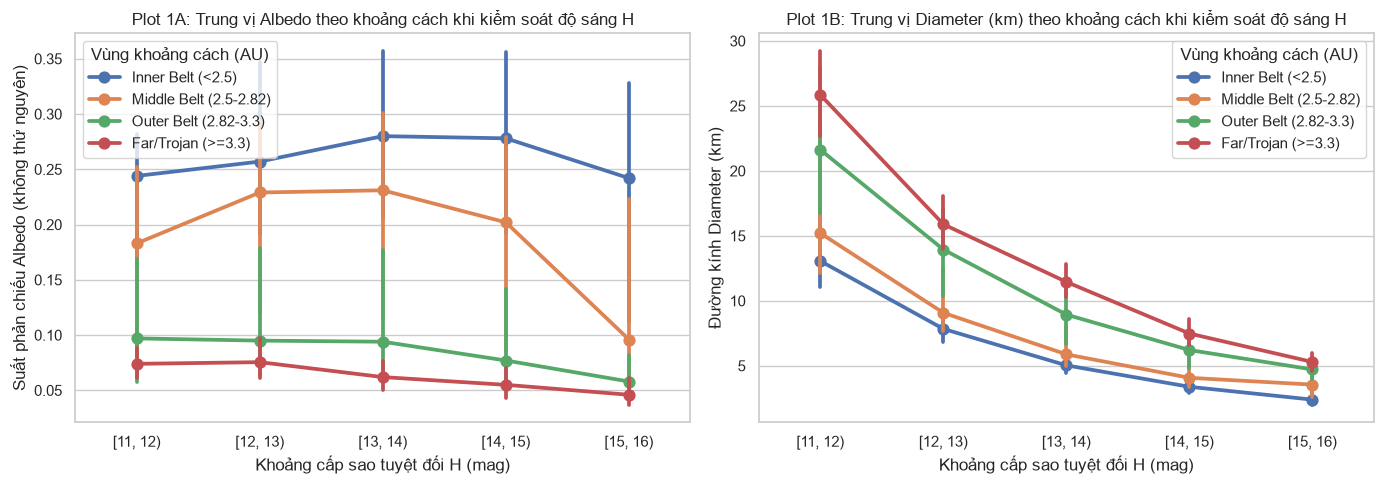

In [8]:
# ### Plot 1: Trung vị Albedo và Diameter (km) theo vùng khoảng cách khi cố định độ sáng H
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.pointplot(data=q2_sub, x="H_bin", y="albedo", hue="heliocentric_zone", estimator=np.median, errorbar=("pi", 50), ax=axes[0])
axes[0].set_title("Plot 1A: Trung vị Albedo theo khoảng cách khi kiểm soát độ sáng H")
axes[0].set_xlabel("Khoảng cấp sao tuyệt đối H (mag)")
axes[0].set_ylabel("Suất phản chiếu Albedo (không thứ nguyên)")
axes[0].legend(title="Vùng khoảng cách (AU)")

sns.pointplot(data=q2_sub, x="H_bin", y="diameter", hue="heliocentric_zone", estimator=np.median, errorbar=("pi", 50), ax=axes[1])
axes[1].set_title("Plot 1B: Trung vị Diameter (km) theo khoảng cách khi kiểm soát độ sáng H")
axes[1].set_xlabel("Khoảng cấp sao tuyệt đối H (mag)")
axes[1].set_ylabel("Đường kính Diameter (km)")
axes[1].legend(title="Vùng khoảng cách (AU)")
plt.tight_layout()
plt.show()

### Plot 2

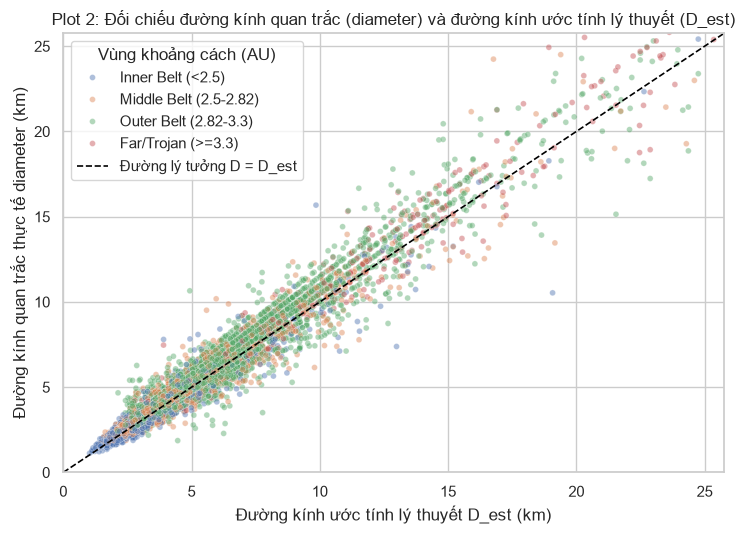

In [9]:
# ### Plot 2: Kiểm chứng công thức biến dẫn xuất D3 (Diameter thực tế vs D_est lý thuyết)
sample_p2 = q2_sub.sample(n=min(10000, len(q2_sub)), random_state=42)
plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(
    data=sample_p2, x="d_est", y="diameter", hue="heliocentric_zone",
    alpha=0.45, s=18
)
max_val = min(sample_p2["diameter"].quantile(0.995), sample_p2["d_est"].quantile(0.995))
plt.plot([0, max_val], [0, max_val], color="black", linestyle="--", linewidth=1.2, label="Đường lý tưởng D = D_est")
plt.xlim(0, max_val)
plt.ylim(0, max_val)
plt.title("Plot 2: Đối chiếu đường kính quan trắc (diameter) và đường kính ước tính lý thuyết (D_est)")
plt.xlabel("Đường kính ước tính lý thuyết D_est (km)")
plt.ylabel("Đường kính quan trắc thực tế diameter (km)")
plt.legend(title="Vùng khoảng cách (AU)")
plt.tight_layout()
plt.show()

## 7. Answer and interpretation
- **Direct answer with specific numerical evidence:** Cả hai quy luật bề mặt tối dần và kích thước lớn dần từ trong ra ngoài Hệ Mặt Trời đều là **quy luật vật lý có thật** chứ không chỉ do thiên lệch quan sát[cite: 3]:
  - Khi giữ cố định độ sáng `H` qua cả 5 tầng từ $[11, 12)$ đến $[15, 16)\text{ mag}$, suất phản chiếu trung vị của Vành đai ngoài (`2.82–3.3 AU`) luôn thấp hơn Vành đai trong (`< 2.5 AU`) từ **$-0.147$** (95% CI: $[-0.1620, -0.1210]$) đến **$-0.201$** (95% CI: $[-0.2040, -0.1970]$)[cite: 3].
  - Trong cùng tầng độ sáng `H`, đường kính trung vị của Vành đai ngoài vẫn lớn hơn Vành đai trong từ **$+8.56\text{ km}$** (tầng $[11, 12)$, CI $[7.42, 9.71]$) đến **$+2.32\text{ km}$** (tầng $[15, 16)$, CI $[2.29, 2.35]$), với tương quan hạng Spearman $\rho(a, D)$ đạt từ **$0.511$ đến $0.646$**[cite: 3].
- **Practical meaning:** Không thể áp dụng một hằng số `albedo` trung bình chung cho toàn bộ Hệ Mặt Trời khi quy đổi từ độ sáng `H` sang đường kính; các mô hình ước lượng kích thước bắt buộc phải hiệu chỉnh `albedo` theo vùng khoảng cách `a` để tránh đánh giá thiếu kích thước của các tiểu hành tinh tối màu ở vùng ngoài.
- **Surprising findings:** Ngay cả khi đã loại bỏ hoàn toàn thiên lệch chọn mẫu bằng cách cố định độ sáng `H`, đường kính trung vị vẫn tăng đơn điệu theo khoảng cách `a`[cite: 3]. Điều này xuất phát trực tiếp từ hệ thức vật lý $D \propto \frac{10^{-0.2H}}{\sqrt{\text{albedo}}}$: để phát ra cùng một lượng ánh sáng biểu kiến (`H` không đổi), một tiểu hành tinh tối màu (`albedo` thấp) ở vành đai ngoài bắt buộc phải có diện tích bề mặt lớn hơn để bù đắp khả năng phản xạ kém.
- **Limitations:** Hai biến `diameter` và `albedo` chỉ hiện diện ở ~14% dữ liệu gốc (các thiên thể được khảo sát hồng ngoại), nên cần thận trọng khi ngoại suy cho quần thể tiểu hành tinh siêu nhỏ ($H > 16\text{ mag}$).
- **Robustness / uncertainty results where applicable:** Trên tầng mẫu tiêu biểu $H \in [13, 14)$, khi loại bỏ các phép đo sai số cao ($\text{diameter\_sigma}/\text{diameter} > 10\%$) và các ngoại lai khổng lồ $> 300\text{ km}$ ($N$ giảm từ $13,210$ xuống $11,696$), chênh lệch trung vị `albedo` gần như bất biến (**$-0.186$** CI $[-0.1928, -0.1800]$ so với **$-0.188$** CI $[-0.1930, -0.1780]$) và độ lớn hiệu ứng tăng nhẹ từ Cliff's $\delta = -0.679$ lên **$-0.702$**[cite: 3].

## LƯU Ý: MỘT SỐ THUẬT NGỮ, ĐỊNH LÝ, ĐỊNH NGHĨA
## 1. Thuật ngữ Cơ học quỹ đạo & Hình học không gian (Câu hỏi 1)
- **Định luật I Kepler:** mọi hành tinh và tiểu hành tinh chuyển động quanh Mặt Trời theo quỹ đạo hình elip, với Mặt Trời nằm tại một trong hai tiêu điểm. Từ định luật này ta có quan hệ giữa bán trục lớn ($a$), độ lệch tâm ($e$), khoảng cách cận nhật ($q$) và viễn nhật ($ad$):$$q = a(1 - e), \qquad ad = a(1 + e)$$
(Trong hình học và thiên văn học, tiêu điểm (focus) là một trong hai điểm cố định đặc biệt nằm trên trục lớn của hình elip, quyết định hình dạng quỹ đạo và sự thay đổi khoảng cách của tiểu hành tinh tới Mặt Trời.)

Giải thích điểm cận nhật (q) và viễn nhật (ad): Chính vì Mặt Trời nằm lệch tại tiêu điểm $F_1$ (còn tiêu điểm thứ hai $F_2$ chỉ là một điểm trống trong không gian), khoảng cách từ tiểu hành tinh tới Mặt Trời thay đổi liên tục khi nó quay quanh quỹ đạo:
+ Đầu mút elip nằm gần tiêu điểm chứa Mặt Trời nhất là cận nhật (q).
+ Đầu mút elip nằm phía đối diện (xa tiêu điểm chứa Mặt Trời nhất) là viễn nhật (ad).
- **Tỷ số quỹ đạo kéo dài:** Theo Định luật I Kepler, đại lượng này rút gọn thành $2e$, giúp đo thuần túy mức độ kéo dài hình học tương đối của quỹ đạo mà không bị phụ thuộc vào kích thước lớn hay nhỏ của quỹ đạo ($a$).
- **Quỷ đạo gần dẹt (lệch tâm cao):** Quỹ đạo hình elip bị kéo dài mạnh (độ lệch tâm $e$ lớn, điểm cận nhật $q$ tiến rất gần Mặt Trời trong khi điểm viễn nhật $ad$ vươn ra rất xa), trái ngược với quỹ đạo gần tròn ($e \approx 0$).
- **Tỷ số cận nhật so với Trái Đất (q_earth_ratio):** Biến dẫn xuất $\frac{q}{1.0\text{ AU}}$, dùng để xác định điểm gần Mặt Trời nhất của tiểu hành tinh nằm bên trong ($< 1$) hay bên ngoài ($> 1$) quỹ đạo trung bình của Trái Đất ($1.0\text{ AU}$).
- **Mặt phẳng hoàng đạo (Ecliptic plane):** Mặt phẳng hình học chứa quỹ đạo chuyển động của Trái Đất quanh Mặt Trời, được chọn làm mặt phẳng tham chiếu chuẩn ($i = 0^\circ$) cho toàn bộ Hệ Mặt Trời.
- **Hiệu ứng hình học 3D:** Sự tương tác vị trí trong không gian ba chiều có xét đến độ nghiêng quỹ đạo ($i$). Khi chiếu lên mặt phẳng 2D, một quỹ đạo dẹt có thể cắt ngang vòng tròn $1\text{ AU}$ của Trái Đất; nhưng trong không gian 3D, nếu góc nghiêng $i$ lớn, tiểu hành tinh sẽ bay vọt lên phía trên hoặc phía dưới mặt phẳng hoàng đạo, làm khoảng cách thực tế tới Trái Đất tăng lên.
- **Khoảng cách hình học (moid — Minimum Orbit Intersection Distance):** Khoảng cách không gian ngắn nhất giữa đường quỹ đạo của tiểu hành tinh và đường quỹ đạo của Trái Đất. Đây là khoảng cách hình học giữa hai quỹ đạo cố định, chưa xét đến việc hai thiên thể có đi qua điểm gần nhất đó vào cùng một thời điểm hay không.
- **Sai số khớp quỹ đạo (rms — Root Mean Square residual):** Độ lệch bình phương trung bình (tính bằng giây cung — arcsec) giữa vị trí quan sát thực tế của tiểu hành tinh trên bầu trời và vị trí tính toán từ mô hình quỹ đạo. Giá trị rms càng nhỏ thì quỹ đạo càng được xác định chính xác.
- **Quỹ đạo chặt:** là quỹ đạo của một tiểu hành tinh đã được tính toán và "khóa" chính xác đường đi trong không gian với biên độ sai số cực nhỏ. **Lọc quỹ đạo chặt (Strict RMS <= 0.5):** Đặt ngưỡng tiêu chuẩn nghiêm ngặt hơn trên cột rms (chỉ giữ lại các tiểu hành tinh có rms <= 0.5 arcsec) để loại bỏ các quỹ đạo mới quan trắc sơ bộ còn nhiều sai số.

## 2. Thuật ngữ Vật lý thiên văn & Thiên lệch quan trắc (Câu hỏi 2)
- **Các khe trống Kirkwood của bán trục lớn `a`:** Những vùng khuyết mật độ tiểu hành tinh tại các vị trí bán trục lớn xác định trong vành đai chính (như $2.50\text{ AU}$, $2.82\text{ AU}$, $3.27\text{ AU}$), hình thành do cộng hưởng hấp dẫn chu kỳ quay với Sao Mộc (tỷ lệ 3:1, 5:2, 2:1). Các khe này được dùng làm ranh giới vật lý tự nhiên để chia Vành đai trong, Vành đai giữa và Vành đai ngoài. Nguyên nhân chính là lực hấp dẫn của Sao Mộc. Sao Mộc có khối lượng rất lớn nên lực hấp dẫn của nó ảnh hưởng đáng kể đến quỹ đạo các tiểu hành tinh. Một số tiểu hành tinh có chu kỳ quay quanh Mặt Trời nằm trong tỷ lệ cộng hưởng quỹ đạo với Sao Mộc (Ví dụ, cộng hưởng 3:1 có nghĩa là: Tiểu hành tinh quay quanh Mặt Trời 3 vòng và Sao Mộc quay quanh Mặt Trời 1 vòng). Sau nhiều vòng quay, lực hấp dẫn của Sao Mộc tác động lặp đi lặp lại lên tiểu hành tinh, khiến quỹ đạo của nó có thể trở nên mất ổn định. Theo thời gian, nhiều tiểu hành tinh bị đẩy ra khỏi những vùng quỹ đạo đó, tạo thành các khe trống.
- **Suất phản chiếu (albedo)/Suất phản chiếu hình học, không thứ nguyên:** Tỷ số giữa độ sáng thực tế của tiểu hành tinh nhìn từ hướng Mặt Trời với độ sáng của một đĩa phẳng lý tưởng phản xạ khuếch tán hoàn hảo cùng diện tích. Vì là tỷ số của hai đại lượng cùng đơn vị ánh sáng nên albedo là đại lượng không thứ nguyên (nhận giá trị từ $0$ đến $1$, phản ánh bề mặt tối hay sáng).
- **Phản xạ bề mặt:** Khả năng hắt lại ánh sáng Mặt Trời của lớp đất đá phủ trên bề mặt tiểu hành tinh.
- **Quy luật bề mặt tối dần:** mô tả hiện tượng suất phản chiếu bề mặt (albedo) của tiểu hành tinh giảm dần một cách có hệ thống khi khoảng cách trung bình tới Mặt Trời (a) tăng lên — nghĩa là tiểu hành tinh càng nằm xa Mặt Trời thì lớp đất đá bề mặt càng sẫm màu và hấp thụ ánh sáng mạnh hơn. Khi đi từ Vành đai trong ra Vành đai ngoài, suất phản chiếu giảm dần.
- **Quy luật tiến hóa vật chất thực sự của Hệ Mặt Trời:** Sự phân hóa thành phần hóa học tự nhiên từ thuở hình thành đĩa tiền hành tinh (là một đám mây khí và bụi có dạng hình đĩa, quay xung quanh một ngôi sao mới hình thành. Đây chính là nơi các hành tinh, tiểu hành tinh, sao chổi và nhiều thiên thể khác có thể được hình thành. Là "nguyên liệu ban đầu" để hình thành một hệ hành tinh như Hệ Mặt Trời của chúng ta.): vùng gần Mặt Trời có nhiệt độ cao làm bay hơi chất dễ bay hơi, để lại các tiểu hành tinh giàu đá silicat và kim loại sáng màu (albedo cao); vùng xa Mặt Trời (qua "đường tuyết") có nhiệt độ thấp nên bảo toàn được các hợp chất carbon hữu cơ và băng tối màu (albedo thấp).
- **Độ sáng tuyệt đối (H — cấp sao tuyệt đối, đơn vị mag):** Độ sáng biểu kiến (là mức độ sáng của một thiên thể (ngôi sao, hành tinh, tiểu hành tinh...) khi chúng ta quan sát nó từ Trái Đất, cho biết một thiên thể trông sáng như thế nào đối với người quan sát) chuẩn hóa của tiểu hành tinh nếu đặt nó cách Mặt Trời $1\text{ AU}$, cách Trái Đất $1\text{ AU}$ và ở góc pha $0^\circ$. Thang đo cấp sao mag là thang logarit ngược: H càng nhỏ thì thiên thể càng sáng (chênh lệch $5\text{ mag}$ tương ứng tỷ lệ độ sáng $100$ lần; $1\text{ mag} \approx 2.512$ lần).
- **Thiên lệch quan sát (H) / Thiên lệch Malmquist / Ảo ảnh chọn mẫu của kính thiên văn:** Hiện tượng sai lệch dữ liệu do giới hạn độ nhạy của kính thiên văn (flux-limited bias): ở khoảng cách `a` càng xa, thiết bị chỉ phát hiện được các thiên thể rất sáng (`H` nhỏ) và bỏ sót các vật thể mờ/nhỏ (`H` lớn). Nếu không kiểm soát `H`, ta sẽ thấy kích thước trung bình ở xa lớn hơn ở gần nhưng phần lớn chỉ là "ảo ảnh" do mẫu ở xa thiếu vắng các vật thể nhỏ.
- **Đo đạc hồng ngoại & Tính chất vật lý hồng ngoại:** Kỹ thuật quan sát bức xạ nhiệt phát ra từ chính tiểu hành tinh (thực hiện bởi các kính viễn vọng không gian như WISE/NEOWISE, IRAS). Khác với ánh sáng khả kiến bị nhập nhằng giữa vật thể nhỏ nhưng sáng với vật thể lớn nhưng tối, bức xạ nhiệt hồng ngoại cho phép tách bạch và đo trực tiếp kích thước `diameter` cùng `albedo`.
- **Sứ mệnh không gian:** Đó là một chuyến hành trình được lên kế hoạch để nghiên cứu hoặc khám phá không gian.

## 3. Khái niệm & Phương pháp Thống kê (Tiêu chí D4 – D6)
- **Cực trị ở phần đuôi phân phối:** Các giá trị nằm ở vùng rìa ngoài cùng của phân phối xác suất (ví dụ nhóm tiểu hành tinh có moid <= 0.05 AU — phần đuôi trái cực nhỏ của biến moid dẫn tới nhãn nguy hiểm PHA = Y). Trong nhiều trường hợp, trung vị không thay đổi nhiều nhưng phần đuôi phân phối giãn rộng làm tỷ lệ biến cố cực trị tăng vọt.
- **Ngưỡng cắt trung vị:** Phương pháp chia một biến liên tục (như span_ratio) thành hai nhóm có số lượng quan sát bằng nhau (50% thấp, 50% cao) lấy giá trị trung vị làm ranh giới.
- **Phân tầng nhị phân:** Chia biến nhiễu liên tục (như độ nghiêng i) thành hai tầng rời rạc qua một mốc cố định (i <= 15° và i > 15°) để thực hiện so sánh công bằng bên trong từng tầng. 
- **Khoảng tin cậy Bootstrap 95% (1,000 lần lặp):** Kỹ thuật tái lấy mẫu ngẫu nhiên có hoàn lại (resampling with replacement) 1.000 lần từ tập mẫu gốc nhằm xây dựng phân phối thực nghiệm của hiệu số trung vị giữa hai nhóm mà không yêu cầu giả định dữ liệu có phân phối chuẩn. Hai đầu mút tại phân vị 2,5% và 97,5% tạo thành khoảng tin cậy 95%. Nếu khoảng tin cậy không chứa giá trị 0, có bằng chứng thống kê cho thấy hiệu số trung vị khác 0 ở mức ý nghĩa 5%.
- **Kiểm định phi tham số Mann-Whitney U:** Kiểm định giả thuyết thống kê dựa trên thứ hạng (rank) để đánh giá sự khác biệt về phân phối giữa hai nhóm độc lập. Phương pháp này phù hợp với dữ liệu thiên văn có phân phối lệch hoặc chứa ngoại lai, do không yêu cầu dữ liệu tuân theo phân phối chuẩn. Khi hai phân phối có hình dạng tương tự nhau, kết quả có thể được diễn giải theo sự khác biệt về vị trí trung tâm.
- **Độ lớn hiệu ứng (Effect size) & Cliff's $\delta$:** Các thước đo định lượng mức độ khác biệt thực tế giữa hai nhóm, bổ sung cho p-value vốn dễ trở nên rất nhỏ khi kích thước mẫu lớn. Hệ số Cliff's (\delta \in [-1,1]) đo chênh lệch giữa xác suất một quan sát ngẫu nhiên ở nhóm A lớn hơn nhóm B và xác suất ngược lại. Giá trị càng gần 0 cho thấy mức độ khác biệt càng nhỏ; giá trị càng gần -1 hoặc +1 cho thấy mức độ khác biệt càng lớn. Theo quy ước phân loại được sử dụng trong nghiên cứu: $|\delta| < 0.147$ (nhỏ), $0.147 \leq |\delta| < 0.33$ (trung bình), $0.33 \leq |\delta| < 0.474$ (khá) và $|\delta| \geq 0.474$ (lớn).
- **Odds Ratio (kèm 95% CI):** Tỷ số chênh được sử dụng cho biến kết quả nhị phân (PHA = Y/N), nhằm so sánh odds thuộc nhóm PHA giữa nhóm có span_ratio cao và nhóm có span_ratio thấp. Nếu OR > 1 và khoảng tin cậy 95% không chứa giá trị 1, có bằng chứng thống kê cho thấy nhóm có span_ratio cao có odds thuộc nhóm PHA lớn hơn nhóm còn lại. (sử dụng để so sánh tỷ số chênh xảy ra một sự kiện giữa hai nhóm, khoảng tin cậy 95% giúp đánh giá độ chính xác và mức độ bất định của ước lượng này.")
- **Hệ số tương quan hạng Spearman $\rho(a, D)$:** Thước đo phi tham số $-1 \leq \rho \leq 1$ đánh giá chiều hướng và mức độ tương quan đơn điệu giữa bán trục lớn của quỹ đạo `a` và đường kính tiểu hành tinh `diameter`. Hệ số dương thể hiện xu hướng đồng biến, hệ số âm thể hiện xu hướng nghịch biến. Do dựa trên thứ hạng thay vì giá trị gốc, Spearman ít nhạy cảm hơn với ngoại lai và có thể phát hiện mối quan hệ đơn điệu phi tuyến.

## 4. Giải thích chi tiết các luận điểm trọng tâm trong bài
- **Tại sao: Phân chia nhóm kéo dài quỹ đạo sang phân vị thứ 75?**: Đây là phép kiểm tra tính vững (Robustness check — D6) nhằm xác minh kết luận không bị phụ thuộc vào cách chia nhóm tùy ý tại trung vị (50%). Khi cắt tại trung vị, các tiểu hành tinh có độ kéo dài trung bình dễ bị gộp vào nhóm "kéo dài". Việc nâng ngưỡng cắt lên Q75 (tức chỉ tách riêng top 25% tiểu hành tinh có quỹ đạo kéo dài cực đoan nhất để so với phần còn lại) giúp kiểm chứng xem xu hướng tác động lên moid có giữ nguyên chiều hướng và gia tăng cường độ hay không.
- **Tại sao: Đường kính tiểu hành tinh phân bố theo quy luật lũy thừa (lệch phải mạnh) nên trung vị và tương quan hạng Spearman chống chịu tốt trước các thiên thể khổng lồ, trong khi việc cố định `H` trực tiếp loại bỏ thiên lệch chọn mẫu theo độ sáng?**:
  + Về phân bố lũy thừa (Power-law): Quá trình va chạm nghiền nát trong Hệ Mặt Trời tạo ra hàng trăm nghìn tiểu hành tinh nhỏ đường kính vài kilomet, nhưng chỉ tồn tại một số rất ít thiên thể khổng lồ (như Ceres $\approx 940\text{ km}$, Vesta $\approx 525\text{ km}$). Nếu dùng trung bình cộng (mean) hay tương quan tuyến tính Pearson, chỉ vài thiên thể khổng lồ này sẽ kéo vọt giá trị thống kê lên làm sai lệch bức tranh chung. Ngược lại, trung vị và Spearman $\rho$ chỉ tính toán dựa trên thứ tự xếp hạng (rank) nên hoàn toàn miễn nhiễm với giá trị cực đại của các ngoại lai khổng lồ.
  + Về việc cố định H: Khi ta phân tầng dữ liệu theo từng khoảng H hẹp (ví dụ $H \in [13, 14)$), ta đang so sánh các tiểu hành tinh ở Vành đai trong và Vành đai ngoài có **cùng mức độ sáng nội tại**. Điều này triệt tiêu hoàn toàn ưu thế phát hiện vật thể sáng của kính thiên văn ở vùng xa (thiên lệch Malmquist), đảm bảo sự khác biệt quan sát được phản ánh đúng bản chất vật lý chứ không phải lỗi chọn mẫu.   
- **Tại sao: Không thể áp dụng một hằng số `albedo` trung bình chung cho toàn bộ Hệ Mặt Trời khi quy đổi từ độ sáng `H` sang đường kính**: Do hơn 85% tiểu hành tinh chưa được đo trực tiếp bằng kính viễn vọng hồng ngoại, các nhà thiên văn buộc phải ước tính đường kính của chúng từ độ sáng H thông qua công thức $D = \frac{1329}{\sqrt{\text{albedo}}} \times 10^{-0.2H}$. Trước đây, nhiều ước tính dùng một hằng số giả định chung (ví dụ albedo = 0.14). Tuy nhiên, kết quả phân tích chỉ ra sự phân hóa rất lớn: Vành đai trong có trung vị albedo $\approx 0.25$ trong khi Vành đai ngoài chỉ khoảng $0.06$. Nếu áp dụng hằng số chung $0.14$ cho một tiểu hành tinh ở Vành đai ngoài, đường kính ước tính sẽ bị nhỏ hơn thực tế tới $\sqrt{0.14 / 0.06} \approx 1.53$ lần — tương đương với việc đánh giá thấp thể tích, khối lượng và động năng va chạm của thiên thể đó tới gần $3.6$ lần ($1.53^3$). 

# Question Q3 – Nhóm tiểu hành tinh nào có dữ liệu vật lý đầy đủ nhất trước và sau chuẩn hóa theo độ sáng H?

## 1. Question and motivation

**Phụ trách: Nghiêm.**

- **Exact question:** Trong các nhóm quỹ đạo đủ điều kiện so sánh, nhóm nào có tỷ lệ bản ghi có cả đường kính (`diameter`) và suất phản chiếu (`albedo`) dương cao nhất? Nhóm đứng đầu có thay đổi khi chuẩn hóa các nhóm về cùng phân bố độ sáng tuyệt đối (`H`) không?
- **Why is it worth answering?** Các nhóm quỹ đạo có thể khác nhau về phân bố `H`. Nếu mức độ đầy đủ của dữ liệu cũng thay đổi theo `H`, thứ hạng theo tỷ lệ thô có thể phụ thuộc vào cơ cấu `H` của từng nhóm. So sánh trước và sau chuẩn hóa giúp kiểm tra điều đó.
- **Who would care?** Các nhà nghiên cứu cần đồng thời số đo đường kính và suất phản chiếu để phân tích đặc điểm vật lý của tiểu hành tinh.
- **What decision could it inform?** Khi chọn mẫu từ danh mục hiện có, người nghiên cứu có thể dùng tỷ lệ thô để ưu tiên nhóm có tỷ lệ bản ghi dùng được cao. Khi muốn so sánh mức độ đầy đủ giữa các nhóm trên cùng cơ cấu `H`, họ có thể dùng tỷ lệ sau chuẩn hóa.

## 2. Data and variables

- **Relevant columns:** `class` (nhóm quỹ đạo), `H` (cấp sao tuyệt đối, mag), `diameter` (đường kính, km) và `albedo` (suất phản chiếu, không có đơn vị).
- **Row meaning / unit of analysis:** Mỗi dòng là một bản ghi tiểu hành tinh. Các bản ghi thiếu đường kính hoặc suất phản chiếu vẫn được tính vào mẫu để xác định tỷ lệ đầy đủ của từng nhóm.
- **Subgroups:** Chia các bản ghi có `class` và `H` thành từng nhóm quỹ đạo, giữ các nhóm có ít nhất 1.000 bản ghi. Trên mẫu này, chia `H` thành 5 tầng theo phân vị. Một nhóm được đưa vào bảng xếp hạng khi có ít nhất 30 bản ghi ở mỗi tầng.
- **Any additional data source needed?** Cả bốn cột đều có trong bảng dữ liệu gốc `df_raw`.

## 3. Depth criteria

- **D1 Combining data:** Không áp dụng. Q3 sử dụng một bảng dữ liệu.
- **D2 Reshaping & time:** Dùng `unstack()` để tạo bảng có hàng là nhóm quỹ đạo và cột là tầng `H`. Bảng này dùng để kiểm tra số bản ghi mỗi ô và vẽ bản đồ nhiệt.
- **D3 Derived variables:** Tạo biến `complete`, nhận giá trị `True` khi cả `diameter` và `albedo` đều dương. Tỷ lệ bản ghi có `complete = True` là thước đo mức đầy đủ của dữ liệu vật lý.
- **D4 Controlling for a confounder:** Tính tỷ lệ đầy đủ trong từng tầng `H` của mỗi nhóm quỹ đạo. Sau đó lấy trung bình có trọng số, dùng cùng tỷ trọng các tầng `H` của toàn mẫu cho mọi nhóm. So sánh thứ hạng trước và sau chuẩn hóa để xem nhóm nào đứng đầu khi có cùng cơ cấu `H`.
- **D5 Quantifying uncertainty:** Không áp dụng. Q3 báo cáo tỷ lệ và thứ hạng theo ước lượng điểm.
- **D6 Robustness check:** Lặp lại phép chuẩn hóa với 4 và 6 tầng `H`, vẫn yêu cầu ít nhất 30 bản ghi mỗi ô. Với mỗi cách chia, đối chiếu nhóm đứng đầu và thứ tự của các nhóm cùng đủ điều kiện với phương án 5 tầng.


## 4. Preprocessing

**Chuẩn bị dữ liệu (D3).** Bỏ dòng trùng hoàn toàn, tạo chỉ số đầy đủ và chia H thành năm tầng phân vị. Giữ các dòng có nhóm quỹ đạo, có H và thuộc nhóm có ít nhất 1.000 bản ghi.

In [2]:
q3 = df_raw.drop_duplicates().copy()
print(f"Bỏ dòng trùng: {len(df_raw):,} → {len(q3):,}")
q3["class"] = q3["class"].astype("string").str.strip().replace("", pd.NA)
for col in ["H", "diameter", "albedo"]:
    q3[col] = pd.to_numeric(q3[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
q3["complete"] = q3["diameter"].gt(0) & q3["albedo"].gt(0)
q3 = q3.dropna(subset=["class", "H"])
print(f"Có class và H: {len(q3):,}")
q3 = q3[q3.groupby("class")["complete"].transform("size") >= 1000]
print(f"Thuộc nhóm có ít nhất 1.000 bản ghi: {len(q3):,}")
q3["H_bin"] = pd.qcut(q3["H"], 5, labels=False, duplicates="drop") + 1

Bỏ dòng trùng: 958,524 → 958,524


Có class và H: 952,261


Thuộc nhóm có ít nhất 1.000 bản ghi: 951,672


## 5. Analysis method

**So sánh có kiểm soát (D4).** Tính tỷ lệ đầy đủ trong từng tầng H, rồi lấy trung bình với cùng bộ trọng số là tỷ trọng các tầng trong mẫu. Chỉ xếp hạng nhóm có ít nhất 30 bản ghi ở mỗi tầng.

In [3]:
q3_groups = q3.groupby(["class", "H_bin"], observed=True)["complete"]
q3_rates = q3_groups.mean().unstack() * 100
q3_counts = q3_groups.size().unstack(fill_value=0)
q3_rates = q3_rates.loc[q3_counts.ge(30).all(axis=1)]
q3_weights = q3["H_bin"].value_counts(normalize=True)
q3_result = pd.DataFrame({
    "Trước chuẩn hóa": q3.groupby("class")["complete"].mean().reindex(q3_rates.index) * 100,
    "Sau chuẩn hóa": q3_rates.mul(q3_weights, axis="columns").sum(axis=1),
}).sort_values("Sau chuẩn hóa", ascending=False)
print(f"Đủ điều kiện xếp hạng: {len(q3_result)}/{len(q3_counts)} nhóm")
q3_table = q3_result.copy()
for col in ["Trước chuẩn hóa", "Sau chuẩn hóa"]:
    q3_table["Hạng " + col.lower()] = q3_table[col].rank(
        ascending=False, method="min"
    ).astype(int)
display(q3_table.round(2))


Đủ điều kiện xếp hạng: 6/9 nhóm


,Trước chuẩn hóa,Sau chuẩn hóa,Hạng trước chuẩn hóa,Hạng sau chuẩn hóa
class,,,,
APO,3.58,27.06,3,1
AMO,2.99,25.71,4,2
MBA,14.15,14.25,2,3
OMB,26.35,12.77,1,4
IMB,2.24,12.19,5,5
MCA,1.79,5.72,6,6


**Thứ hạng có phụ thuộc vào việc chọn 5 tầng H? (D6)** Chia lại mẫu thành 4 và 6 tầng, giữ ngưỡng 30 bản ghi mỗi ô. Với mỗi cách chia, đối chiếu thứ tự với phương án 5 tầng trên các nhóm đủ điều kiện ở cả hai phương án.

In [4]:
q3_checks = []
for k in (4, 6):
    bins = pd.qcut(q3["H"], k, labels=False, duplicates="drop")
    groups = q3.groupby([q3["class"], bins], observed=True)["complete"]
    counts = groups.size().unstack(fill_value=0)
    rates = groups.mean().unstack()
    weights = bins.value_counts(normalize=True)
    adjusted = rates.loc[counts.ge(30).all(axis=1)].mul(weights, axis=1).sum(axis=1)
    common = adjusted.index.intersection(q3_result.index)
    baseline = q3_result.loc[common, "Sau chuẩn hóa"]
    ranks = adjusted.loc[common].rank(ascending=False, method="min")
    base_ranks = baseline.rank(ascending=False, method="min")
    changed = ranks.index[ranks.ne(base_ranks)].tolist()
    if len(common) < 2:
        comparison = "Chưa đủ nhóm chung để so sánh"
    elif changed:
        comparison = "Đổi hạng: " + ", ".join(changed)
    else:
        comparison = "Giữ nguyên thứ tự"
    leaders = ", ".join(adjusted.index[adjusted.eq(adjusted.max())]) or "Không có"
    q3_checks.append([k, len(common), leaders, comparison])
display(pd.DataFrame(q3_checks, columns=[
    "Số tầng H", "Số nhóm chung với 5 tầng",
    "Đứng đầu trong các nhóm đủ điều kiện", "Thứ hạng trong nhóm chung"
]))


,Số tầng H,Số nhóm chung với 5 tầng,Đứng đầu trong các nhóm đủ điều kiện,Thứ hạng trong nhóm chung
0,4,6,APO,Giữ nguyên thứ tự
1,6,6,APO,Giữ nguyên thứ tự


## 6. Results and visualizations

**Đọc hai hình.** Mỗi ô của bản đồ nhiệt cho biết tỷ lệ có đủ cả hai phép đo trong một nhóm quỹ đạo và một tầng H. Ở biểu đồ cột, hai cột của cùng một nhóm dùng cùng dữ liệu, nhưng cột sau chuẩn hóa dùng trọng số H chung.

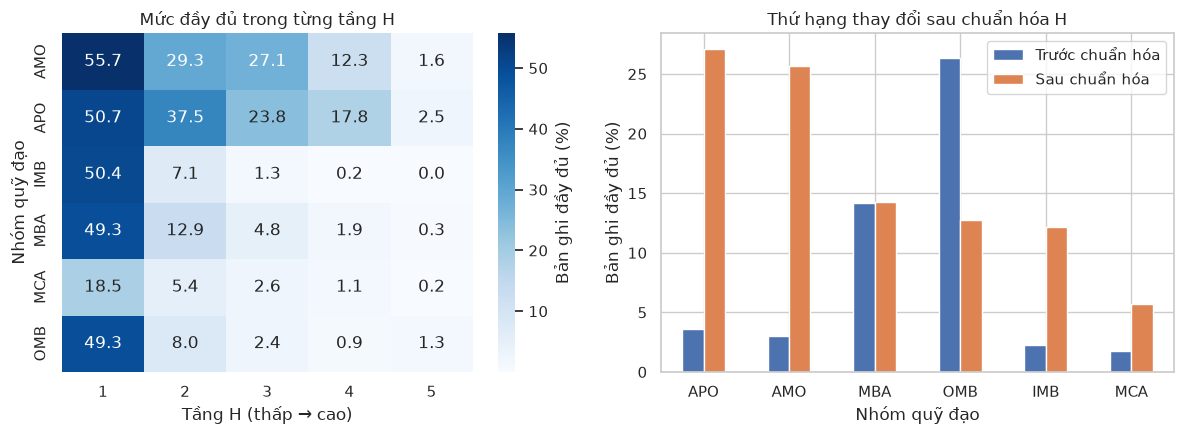

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(q3_rates, annot=True, fmt=".1f", cmap="Blues", ax=ax1,
            cbar_kws={"label": "Bản ghi đầy đủ (%)"})
ax1.set(title="Mức đầy đủ trong từng tầng H", xlabel="Tầng H (thấp → cao)", ylabel="Nhóm quỹ đạo")
q3_result.plot.bar(ax=ax2, rot=0)
ax2.set(title="Thứ hạng thay đổi sau chuẩn hóa H", xlabel="Nhóm quỹ đạo", ylabel="Bản ghi đầy đủ (%)")
fig.tight_layout()
plt.show()

## 7. Answer and interpretation

**Kết luận.** Trong sáu nhóm quỹ đạo đủ điều kiện, **OMB** có tỷ lệ bản ghi có đủ cả đường kính và suất phản chiếu cao nhất (**26,35%**). Sau khi chuẩn hóa để các nhóm có cùng phân bố độ sáng tuyệt đối H, **APO** đứng đầu (**27,06%**). Như vậy, câu trả lời cho việc nhóm nào có dữ liệu vật lý đầy đủ nhất phụ thuộc vào việc có tính đến sự khác biệt về phân bố H giữa các nhóm hay không.

**Kiểm tra độ vững (D6).** Khi đổi từ 5 tầng H sang 4 hoặc 6 tầng, cả sáu nhóm chung đều giữ nguyên thứ hạng sau chuẩn hóa. APO đứng đầu trong cả ba cách chia. Kết quả này cho thấy thứ hạng ổn định với những cách chia tầng đã thử.

In [6]:
for col in ["Trước chuẩn hóa", "Sau chuẩn hóa"]:
    rates = q3_result[col]
    top = ", ".join(rates.index[rates.eq(rates.max())])
    print(f"{col}: {top} đứng đầu ({rates.max():.2f}% bản ghi đầy đủ).")
print(f"Phương án 5 tầng có {len(q3_result)} nhóm đủ điều kiện.")
for k, n, leaders, comparison in q3_checks:
    print(f"{k} tầng H: {leaders} đứng đầu. So với 5 tầng trên {n} nhóm chung: {comparison}.")
print("Các thứ hạng dựa trên ước lượng điểm; phân tích chưa kiểm định chênh lệch giữa hai nhóm dẫn đầu.")

Trước chuẩn hóa: OMB đứng đầu (26.35% bản ghi đầy đủ).
Sau chuẩn hóa: APO đứng đầu (27.06% bản ghi đầy đủ).
Phương án 5 tầng có 6 nhóm đủ điều kiện.
4 tầng H: APO đứng đầu. So với 5 tầng trên 6 nhóm chung: Giữ nguyên thứ tự.
6 tầng H: APO đứng đầu. So với 5 tầng trên 6 nhóm chung: Giữ nguyên thứ tự.
Các thứ hạng dựa trên ước lượng điểm; phân tích chưa kiểm định chênh lệch giữa hai nhóm dẫn đầu.


**Ý nghĩa và giới hạn.** Khi chọn nhóm để phân tích đường kính và suất phản chiếu, tỷ lệ thô cho biết mức bao phủ thực tế của danh mục. Tỷ lệ chuẩn hóa trả lời câu hỏi khác: nếu các nhóm có cùng cơ cấu H, nhóm nào có dữ liệu đầy đủ hơn? Kết quả chỉ áp dụng cho các nhóm đủ mẫu ở mọi tầng.

---

# Question Q4 – C hay S có tỷ lệ bề mặt tối cao hơn khi so cùng khoảng đường kính?

**Phụ trách: Kiệt.**

## 1. Câu hỏi và mục đích

**Ở cùng khoảng đường kính, nhóm tiểu hành tinh C hay S có tỷ lệ bề mặt tối cao hơn?**

C và S là hai **loại phổ**, được phân biệt dựa trên đặc điểm ánh sáng phản xạ; đây không
phải nhóm quỹ đạo. Bài này gọi bề mặt **tối khi albedo < 0.10**, một ngưỡng phân tích đã chọn.
So cùng khoảng đường kính giúp giảm ảnh hưởng do hai nhóm có thành phần kích thước khác nhau.

## 2. Dữ liệu và biến

Mỗi dòng là một đối tượng. CSV gốc cung cấp `pdes` (mã đối tượng), `diameter` (km),
`albedo` (suất phản chiếu hình học). Bảng **NASA/JPL** bổ sung `spec_B` (nhãn phổ SMASSII).
Chỉ so nhãn đúng bằng **C** và **S**, không gộp các nhãn như Ch hay Sq.

## 3. Tiêu chí chiều sâu

- **D1:** Ghép nhãn JPL bằng `pdes`, kiểm tra khóa và số dòng trước/sau.
- **D2:** Pivot kết quả thành bảng C/S theo khoảng đường kính.
- **D3:** Tạo chỉ số tối/không tối và khoảng đường kính.
- **D4:** So sánh C/S trong từng khoảng có đủ dữ liệu cho cả hai nhóm.

**Đọc nguồn.** Dùng `df_raw` đã nạp ở đầu notebook. Dùng đúng CSV em đã tải và bản JPL đã lưu; không tải bản mới khi chạy lại.
Dấu vân tay kiểm tra file JPL khớp metadata. Các kiểm tra `assert` dừng nếu cấu trúc nguồn không đúng.

In [16]:
%matplotlib inline
import hashlib
import json
from IPython.display import display, Markdown

q4_columns = ["id", "pdes", "diameter", "albedo"]
q4_catalogue = df_raw[q4_columns].copy()
q4_repo = Path.cwd()
if not (q4_repo / "data/external/jpl_smassii_taxonomy.json").is_file():
    q4_repo = q4_repo.parent
q4_metadata = json.loads((q4_repo / "data/external/jpl_smassii_metadata.json").read_text(encoding="utf-8"))
q4_source = (q4_repo / "data/external/jpl_smassii_taxonomy.json").read_bytes()
assert hashlib.sha256(q4_source).hexdigest() == q4_metadata["sha256"]
q4_payload = json.loads(q4_source)
assert q4_payload["fields"] == ["spkid", "pdes", "spec_B"]
assert len(q4_payload["data"]) == int(q4_payload["count"]) == int(q4_metadata["count"])
q4_taxonomy = pd.DataFrame(q4_payload["data"], columns=q4_payload["fields"]).astype("string")
assert q4_taxonomy.notna().all().all()
assert q4_taxonomy["spec_B"].str.strip().ne("").all()
assert q4_taxonomy["spec_B"].eq(q4_taxonomy["spec_B"].str.strip()).all()
print(f"CSV: {len(df_raw):,} dòng | JPL: {len(q4_taxonomy):,} dòng")
print("Bản JPL tải lúc (UTC):", q4_metadata["retrieved_at_utc"])

CSV: 958,524 dòng | JPL: 1,666 dòng
Bản JPL tải lúc (UTC): 2026-11-21T20:41:04.929645+00:00


## 4. Tiền xử lý

**Ghép bảng (D1).** Bỏ khoảng trắng ngoài cùng của khóa, yêu cầu mã không thiếu, trống hoặc lặp.
Left join giữ toàn bộ CSV; kiểm tra các cột gốc không đổi. Báo số khớp và không khớp ở cả hai nguồn.

In [17]:
for q4_table in [q4_catalogue, q4_taxonomy]:
    q4_table["key"] = q4_table["pdes"].astype("string").str.strip()
    assert q4_table["key"].notna().all() and q4_table["key"].ne("").all()
    assert q4_table["key"].is_unique, "Mã lặp: cần kiểm tra trước khi ghép."
assert q4_catalogue["id"].notna().all() and q4_catalogue["id"].is_unique
q4_merged = q4_catalogue.merge(q4_taxonomy[["key", "spec_B"]], on="key", how="left",
                         validate="one_to_one", indicator=True, sort=False)
assert len(q4_merged) == len(q4_catalogue)
pd.testing.assert_frame_equal(q4_merged[q4_columns], df_raw[q4_columns])
q4_matched = q4_merged["_merge"].eq("both")
assert q4_matched.equals(q4_merged["spec_B"].notna())
q4_external_unmatched = q4_taxonomy.loc[~q4_taxonomy["key"].isin(q4_catalogue["key"])].copy()
q4_audit = pd.Series({"CSV trước ghép": len(q4_catalogue), "CSV sau ghép": len(q4_merged),
                   "CSV khớp JPL": int(q4_matched.sum()), "CSV không khớp": int((~q4_matched).sum()),
                   "JPL không khớp CSV": len(q4_external_unmatched)})
display(q4_audit.to_frame("Số dòng"))
print("Mã JPL không khớp:", ", ".join(q4_external_unmatched["pdes"]))

,Số dòng
CSV trước ghép,958524
CSV sau ghép,958524
CSV khớp JPL,1659
CSV không khớp,956865
JPL không khớp CSV,7


Mã JPL không khớp: 612050, 612103, 612199, 612267, 826914, 826946, 875207


**Chọn mẫu (D3).** Chỉ giữ C/S có đường kính và albedo hữu hạn, dương; không điền thiếu bằng 0.
Chia đường kính thành `(0,5]`, `(5,10]`, `(10,20]`, `(20,50]`, `>50` km;
`(5,10]` nghĩa là lớn hơn 5 và không quá 10. Các mốc này là quy ước phân tích.

In [18]:
q4_cs = q4_merged.loc[q4_merged["spec_B"].isin(["C", "S"])].copy()
q4_valid = np.isfinite(q4_cs[["diameter", "albedo"]]).all(axis=1)
q4_valid &= q4_cs["diameter"].gt(0) & q4_cs["albedo"].gt(0)
q4_surface = q4_cs.loc[q4_valid].copy()
q4_surface["is_dark"] = q4_surface["albedo"] < 0.10
q4_labels = ["(0, 5]", "(5, 10]", "(10, 20]", "(20, 50]", ">50"]
q4_surface["size_bin"] = pd.cut(q4_surface["diameter"], [0, 5, 10, 20, 50, np.inf], labels=q4_labels)
assert q4_surface["size_bin"].notna().all()
q4_steps = pd.DataFrame({"Bước": ["CSV sau ghép", "Nhãn C/S", "Đủ hai phép đo"],
                      "Số dòng": [len(q4_merged), len(q4_cs), len(q4_surface)]})
q4_steps["Loại so với bước trước"] = q4_steps["Số dòng"].shift(1) - q4_steps["Số dòng"]
display(q4_steps)

,Bước,Số dòng,Loại so với bước trước
0,CSV sau ghép,958524,NaN
1,Nhãn C/S,596,957928.0
2,Đủ hai phép đo,508,88.0


## 5. Phương pháp phân tích

**Tỷ lệ tối = số đối tượng có albedo < 0.10 / số đối tượng đủ dữ liệu × 100%.**
Tính riêng theo loại phổ và khoảng đường kính, rồi pivot để đặt C/S cạnh nhau (D2).
Chỉ so sánh chính ở khoảng có **ít nhất 30 C và 30 S** (D4). Đây là quy tắc số lượng,
không bảo đảm hai nhóm hoàn toàn tương đương; các khoảng ít mẫu vẫn được báo trong bảng.

In [19]:
q4_grouped = q4_surface.groupby(["size_bin", "spec_B"], observed=True)["is_dark"].agg(
    n="size", dark_n="sum", dark_fraction="mean").reset_index()
q4_grouped["dark_pct"] = q4_grouped["dark_fraction"] * 100
q4_counts = q4_grouped.pivot(index="size_bin", columns="spec_B", values="n").reindex(columns=["C", "S"])
q4_rates = q4_grouped.pivot(index="size_bin", columns="spec_B", values="dark_pct").reindex(columns=["C", "S"])
q4_keep = q4_counts.ge(30).all(axis=1) & q4_rates.notna().all(axis=1)
assert q4_keep.any(), "Không đủ khoảng để so sánh C/S."
q4_result = pd.DataFrame({"C (n)": q4_counts["C"], "S (n)": q4_counts["S"],
                       "C tối (%)": q4_rates["C"], "S tối (%)": q4_rates["S"],
                       "Dùng so sánh": q4_keep})
display(q4_result.round(2))
q4_common_rates, q4_common_counts = q4_rates.loc[q4_keep], q4_counts.loc[q4_keep]
q4_common = q4_surface.loc[q4_surface["size_bin"].isin(q4_common_rates.index)].copy()
assert q4_grouped["n"].sum() == len(q4_surface)
assert len(q4_common) == int(q4_common_counts.to_numpy().sum())
print(f"Giữ khoảng đủ C/S: {len(q4_surface)} → {len(q4_common)} đối tượng, {int(q4_keep.sum())} khoảng.")

,C (n),S (n),C tối (%),S tối (%),Dùng so sánh
size_bin,,,,,
"(0, 5]",6,44,50.00,4.55,False
"(5, 10]",10,138,20.00,0.00,False
"(10, 20]",40,80,77.50,1.25,True
"(20, 50]",31,55,80.65,1.82,True
>50,56,48,100.00,0.00,True


Giữ khoảng đủ C/S: 508 → 310 đối tượng, 3 khoảng.


## 6. Kết quả và hai biểu đồ

**Hình 1 — So sánh tỷ lệ tối.** Đọc hai cột C/S trong cùng khoảng. Nhãn `n` là số
đối tượng dùng làm mẫu số; cột cao hơn nghĩa là tỷ lệ tối cao hơn.

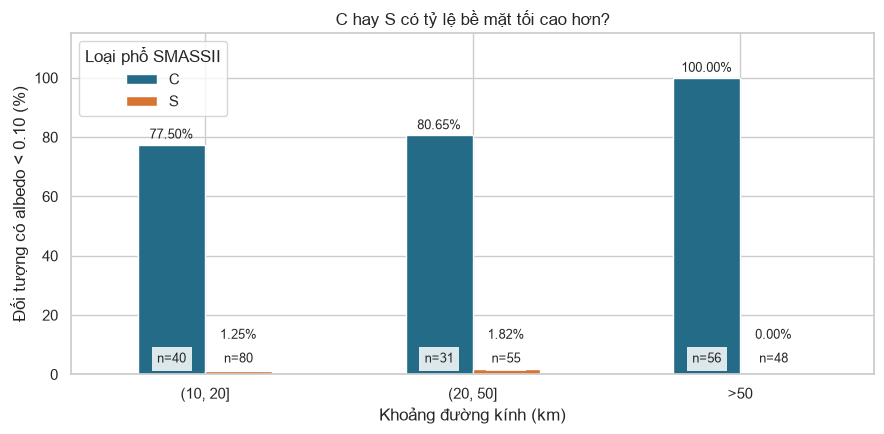

In [20]:
ax = q4_common_rates.plot.bar(figsize=(9, 4.5), color=["#246b88", "#d77432"], rot=0)
for label, bars in zip(["C", "S"], ax.containers):
    for band, bar in zip(q4_common_rates.index, bars):
        x = bar.get_x() + bar.get_width()/2
        ax.text(x, max(bar.get_height()+2, 12), f"{bar.get_height():.2f}%", ha="center", fontsize=9)
        ax.text(x, 4, f"n={int(q4_common_counts.loc[band, label])}", ha="center", fontsize=9,
                bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"})
ax.set(title="C hay S có tỷ lệ bề mặt tối cao hơn?", xlabel="Khoảng đường kính (km)",
       ylabel="Đối tượng có albedo < 0.10 (%)", ylim=(0, 115))
ax.legend(title="Loại phổ SMASSII")
plt.tight_layout()
plt.show()

**Hình 2 — Albedo thực tế.** Mỗi khung dùng cùng khoảng đường kính như hình 1.
Đường giữa hộp là trung vị; đường ngang đứt là ngưỡng tối 0.10.
Hộp thấp hơn biểu thị albedo thấp hơn. Hình dùng toàn bộ mẫu so sánh, không lấy mẫu ngẫu nhiên.

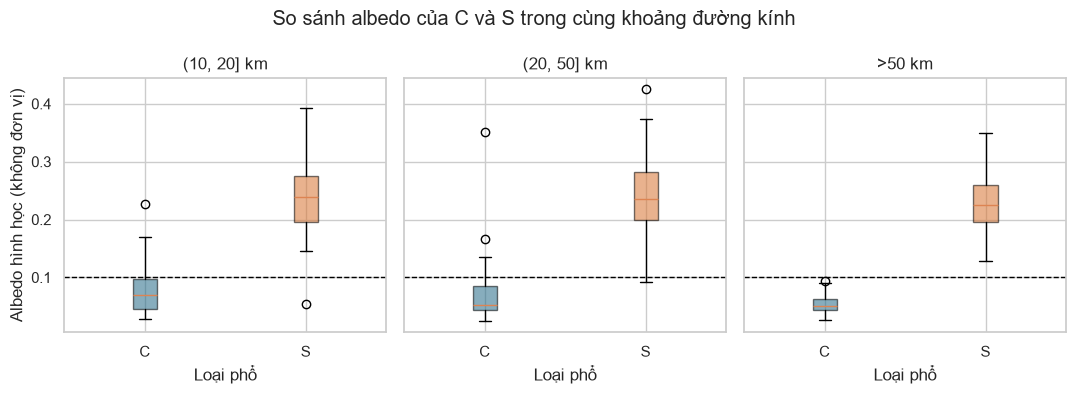

In [21]:
fig, axes = plt.subplots(1, len(q4_common_rates), figsize=(11, 4), sharey=True, squeeze=False)
for ax, band in zip(axes[0], q4_common_rates.index):
    values = [q4_common.loc[q4_common["size_bin"].eq(band) & q4_common["spec_B"].eq(t), "albedo"]
              for t in ["C", "S"]]
    boxes = ax.boxplot(values, tick_labels=["C", "S"], patch_artist=True)
    for box, color in zip(boxes["boxes"], ["#246b88", "#d77432"]):
        box.set_facecolor(color)
        box.set_alpha(0.55)
    ax.axhline(0.10, color="black", linestyle="--", linewidth=1)
    ax.set(title=f"{band} km", xlabel="Loại phổ")
axes[0, 0].set_ylabel("Albedo hình học (không đơn vị)")
fig.suptitle("So sánh albedo của C và S trong cùng khoảng đường kính")
fig.tight_layout()
plt.show()

## 7. Trả lời và diễn giải

In [22]:
q4_all_higher = bool(q4_common_rates["C"].gt(q4_common_rates["S"]).all())
q4_verdict = ("C có tỷ lệ bề mặt tối cao hơn S ở tất cả các khoảng đủ mẫu."
           if q4_all_higher else "Không có một nhóm cao hơn nhất quán ở mọi khoảng; xem bảng từng khoảng.")
q4_numbers = "; ".join(f"**{b} km: {q4_common_rates.loc[b, 'C']:.2f}% so với {q4_common_rates.loc[b, 'S']:.2f}%**"
                    for b in q4_common_rates.index)
display(Markdown(f"**Kết luận.** {q4_verdict} Trong **{len(q4_common)} đối tượng** thuộc "
                 f"**{len(q4_common_rates)} khoảng**, tỷ lệ C so với S lần lượt là {q4_numbers}. "
                 "Như vậy, khác biệt vẫn xuất hiện khi so trong cùng khoảng đường kính."))

**Kết luận.** C có tỷ lệ bề mặt tối cao hơn S ở tất cả các khoảng đủ mẫu. Trong **310 đối tượng** thuộc **3 khoảng**, tỷ lệ C so với S lần lượt là **(10, 20] km: 77.50% so với 1.25%**; **(20, 50] km: 80.65% so với 1.82%**; **>50 km: 100.00% so với 0.00%**. Như vậy, khác biệt vẫn xuất hiện khi so trong cùng khoảng đường kính.

**Ý nghĩa và giới hạn.** Trong mẫu có nhãn và đủ đo đạc, C có xu hướng albedo thấp hơn S.
Kết quả chỉ áp dụng cho các khoảng đủ mẫu; không đại diện toàn bộ danh mục và không chứng minh nhân quả.
Ngưỡng 0.10 là lựa chọn phân tích, khoảng `>50` còn rộng; bản rút gọn không ước lượng khoảng tin cậy.

**Lời nói gợi ý.** “Mình ghép nhãn phổ JPL vào CSV bằng mã đối tượng. Sau khi chọn C/S đủ
dữ liệu, mình so tỷ lệ albedo dưới 0.10 trong cùng khoảng đường kính. Hình một cho thấy C
có tỷ lệ tối cao hơn ở cả ba khoảng; hình hai cho thấy albedo của C thường thấp hơn.
Kết luận này chỉ dành cho mẫu có dữ liệu, chưa thể áp dụng cho toàn bộ tiểu hành tinh.”

Nguồn: [Kaggle — Asteroid Dataset](https://www.kaggle.com/datasets/sakhawat18/asteroid-dataset),
CSV đã tải; [NASA/JPL — trường spec_B và pdes](https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html),
bản JSON/metadata trong `data/external/`. Hai nguồn có thể khác thời điểm.